# SemEval-2014 Restaurants: sonuç analizi

Bu notebook, Qwen3 1.7B (Ollama) ile yapılan **sentiment classification + aspect extraction** deneylerinin sonuçlarını görselleştirir.

- **Test seti** (`data/absa_120.json`, 60 positive + 60 negative): 1–12. bölümlerdeki deneyler ve nihai sonuç (14. bölüm).
- **Dev seti** (`data/absa_dev_80.json`, 40 positive + 40 negative, test setiyle çakışmaz): iyileştirme yöntemlerinin karşılaştırılıp seçildiği set (13. bölüm).

**Nihai sistem:** v4_reason (çıktıda kısa bir gerekçe alanı) + Qwen3 1.7B Q4 + temperature 0 + JSON şeması. Test setinde sentiment %99,2, aspect exact match %93,3, joint accuracy %92,5, JSON ilk deneme başarısı %100.

| Deney | Model | Prompt | JSON şeması |
|---|---|---|---|
| **v1** | `absa-model-v1` | Ayrıntılı prompt, önce sentiment sonra aspect | Yok |
| **v2** | `absa-model-v2` | Ayrıntılı prompt, önce aspect sonra sentiment (**ana sistem**) | Yok |
| **v2 + schema** | `absa-model-v2` | v2 ile aynı | Var |
| **weak** | `absa-model-weak` | 3 satırlık kısa prompt, format ve aspect kuralı yok | Yok |
| **weak + schema** | `absa-model-weak` | weak ile aynı | Var |
| **v3 + schema** | `absa-model-v3` | weak + v2'nin aspect kuralları | Var |

Model ve parametre deneyleri (10–12. bölümler) v2 prompt'uyla yapıldı:

| Deney | Değişen | Sonuç dosyası |
|---|---|---|
| **v2 Q4** | Temel: `qwen3:1.7b-q4_K_M`, temperature 0, süre ölçümüyle yeniden çalıştırıldı | `results_v2_q4_timed.json` |
| **v2 Q8** | Model `qwen3:1.7b-q8_0` | `results_v2_q8.json` |
| **Temperature** | 0,3 / 0,7 / 1,0, her biri 3 seed | `results_v2_temp{t}_seed{s}.json` |
| **v2 + think** | Qwen3 düşünme modu açık, `num_predict 2048` | `results_v2_think.json` |

Metrikler `evaluate.py` içindeki fonksiyonlarla hesaplanır, böylece buradaki sayılar komut satırı çıktısıyla aynıdır.

**Klasör yapısı:** Test seti sonuçları `results/test/`, dev seti sonuçları `results/dev/`, Modelfile'lar `modelfiles/` klasöründedir.

**Not:** weak ve v3 prompt'ları, v2'nin bu 120 örnekteki sonuçları incelendikten sonra tasarlandı. Bu yüzden ana sonuç v2'dir. weak ve v3 keşif amaçlı deneylerdir.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

import evaluate

RESULT_FILES = {
    "v1": "results/test/results_v1.json",
    "v2": "results/test/results_v2.json",
    "v2 + schema": "results/test/results_v2_schema.json",
    "weak": "results/test/results_weak.json",
    "weak + schema": "results/test/results_weak_schema.json",
    "v3 + schema": "results/test/results_v3_schema.json",
}

results = {name: evaluate.load_results(path) for name, path in RESULT_FILES.items()}
metrics = {name: evaluate.evaluate(records) for name, records in results.items()}

word_counts = {record["id"]: record["word_count"] for record in evaluate.load_results("data/absa_120.json")}

# Grafik renkleri: her deney her grafikte aynı rengi kullanır
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
COLORS = {
    "v1": "#2a78d6",
    "v2": "#eb6834",
    "v3 + schema": "#1baf7a",
    "weak + schema": "#eda100",
    "v2 Q4": "#eb6834",
    "v2 Q8": "#6250d6",
    "v2 + think": "#1c5cab",
}
SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelcolor": INK_SECONDARY,
    "ytick.labelcolor": INK_SECONDARY,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "legend.frameon": False,
    "font.size": 10,
})


def style_bar_axis(ax, title, ylabel):
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")


def grouped_bars(ax, categories, series, labels=None):
    # series: {deney adı: [değerler]}, labels: {deney adı: [çubuk üstü yazılar]}
    x = np.arange(len(categories))
    width = 0.8 / len(series)

    for index, (name, values) in enumerate(series.items()):
        positions = x - 0.4 + width * (index + 0.5)
        bars = ax.bar(positions, values, width - 0.03, color=COLORS[name], label=name)

        texts = labels[name] if labels else [str(v) for v in values]
        for bar, text in zip(bars, texts):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), text,
                    ha="center", va="bottom", color=INK_SECONDARY, fontsize=8)

    ax.set_xticks(x, categories)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=len(series))

## 1. Metrik tablosu

In [2]:
metrics_table = pd.DataFrame(metrics).round(3)
metrics_table

,v1,v2,v2 + schema,weak,weak + schema,v3 + schema
JSON first-try success,1.000,1.000,1.000,0.350,1.000,1.000
JSON parsed after cleaning,1.000,1.000,1.000,1.000,1.000,1.000
Valid schema,1.000,1.000,1.000,1.000,1.000,1.000
Parse stage: direct,NaN,NaN,1.000,0.350,1.000,1.000
Parse stage: cleaned,NaN,NaN,0.000,0.650,0.000,0.000
Parse stage: extracted,NaN,NaN,0.000,0.000,0.000,0.000
Parse stage: failed,NaN,NaN,0.000,0.000,0.000,0.000
Avg seconds per sample,NaN,NaN,0.761,0.797,0.718,0.677
positive precision,1.000,1.000,1.000,1.000,1.000,1.000
positive recall,0.867,0.883,0.883,0.983,0.983,0.967


## 2. JSON güvenilirliği: parser ve JSON şemasının etkisi

İlk denemede geçerli JSON, prompt ve şemaya göre nasıl değişiyor ve parser hangi aşamada kaç çıktıyı kurtarıyor? Parser aşaması yalnızca `run.py`'nin yeni sürümüyle çalıştırılan deneylerde kayıtlı (v1 ve v2'de bu bilgi yok, ikisinde de 120/120 ilk denemede başarılı).

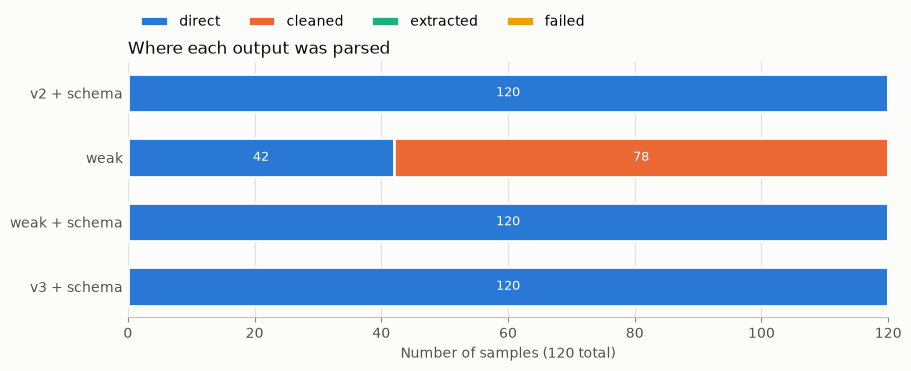

,v2 + schema,weak,weak + schema,v3 + schema
direct,120,42,120,120
cleaned,0,78,0,0
extracted,0,0,0,0
failed,0,0,0,0


In [3]:
stage_runs = ["v2 + schema", "weak", "weak + schema", "v3 + schema"]
stages = ["direct", "cleaned", "extracted", "failed"]
stage_colors = {"direct": "#2a78d6", "cleaned": "#eb6834", "extracted": "#1baf7a", "failed": "#eda100"}

stage_table = pd.DataFrame({
    run: [sum(r.get("parse_stage") == stage for r in results[run]) for stage in stages]
    for run in stage_runs
}, index=stages)

fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
y = np.arange(len(stage_runs))[::-1]
left = np.zeros(len(stage_runs))

for stage in stages:
    values = stage_table.loc[stage, stage_runs].to_numpy()
    ax.barh(y, values, left=left, color=stage_colors[stage], label=stage,
            edgecolor=SURFACE, linewidth=2, height=0.6)
    for yi, value, start in zip(y, values, left):
        if value > 0:
            ax.text(start + value / 2, yi, str(value), ha="center", va="center",
                    color="#ffffff" if stage != "failed" else INK, fontsize=9)
    left += values

ax.set_yticks(y, stage_runs)
ax.set_xlim(0, 120)
ax.set_xlabel("Number of samples (120 total)")
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_title("Where each output was parsed", loc="left")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=4)
plt.show()

stage_table

**Yorum:**
- Format kuralı içermeyen **weak** prompt'ta çıktıların yalnızca 42'si (%35) ilk denemede ayrıştırılabildi. 78'i Markdown çitleri (```` ```json ````) içindeydi ve parser'ın temizleme aşaması (`cleaned`) hepsini kurtardı.
- Aynı prompt'a **JSON şeması** eklenince bütün çıktılar ilk denemede geçerli oldu. Şema format sorununu kaynağında çözüyor.
- Ayrıntılı prompt'larda (v1, v2) şema olmadan da 120/120 başarı var. Parser'ın üçüncü aşaması (`extracted`, sohbet girişi temizliği) hiçbir deneyde gerekmedi. (Sonradan yapılan v5_cot deneyinde ise 120 çıktının hepsi bu aşamayla kurtarıldı, bkz. `parser_ablation.py`.)

## 3. Confusion matrix

Satırlar gerçek etiketi (gold), sütunlar modelin tahminini gösterir. Bütün matrisler aynı renk ölçeğini kullanır. Hiçbir deneyde geçersiz (invalid) çıktı olmadığı için yalnızca iki etiket gösterilir.

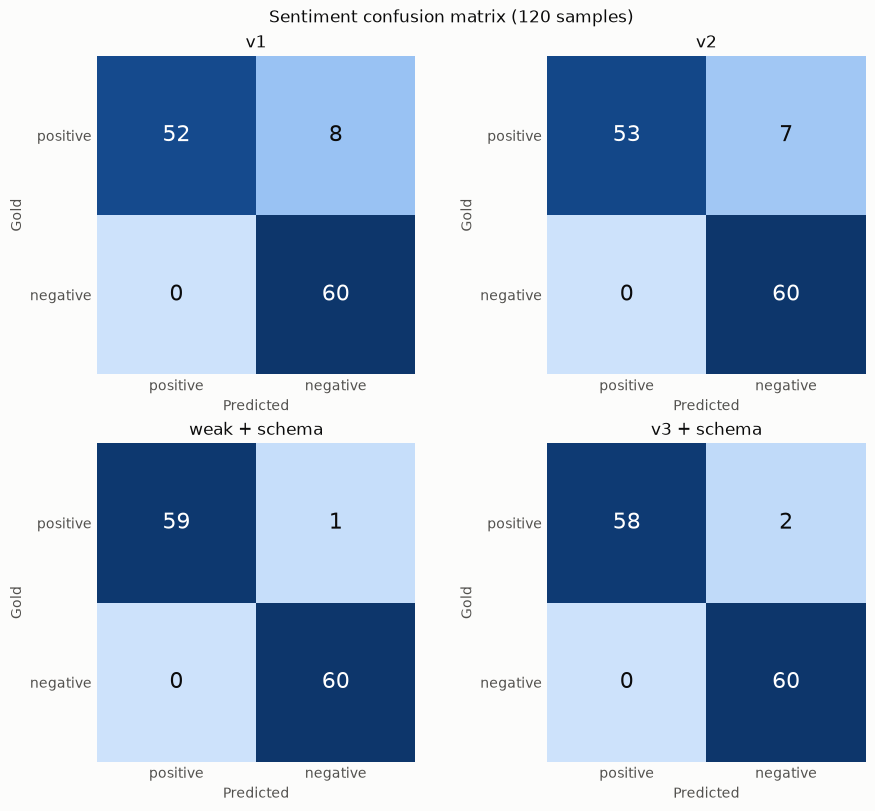

In [4]:
def confusion_matrix(records):
    matrix = np.zeros((2, 2), dtype=int)

    for record in records:
        predicted, _ = evaluate.get_prediction(record)
        if predicted not in evaluate.LABELS:
            continue
        row = evaluate.LABELS.index(record["gold_sentiment"])
        column = evaluate.LABELS.index(predicted)
        matrix[row, column] += 1

    return matrix


matrix_runs = ["v1", "v2", "weak + schema", "v3 + schema"]
fig, axes = plt.subplots(2, 2, figsize=(9, 8), constrained_layout=True)

for ax, name in zip(axes.flat, matrix_runs):
    matrix = confusion_matrix(results[name])
    ax.imshow(matrix, cmap=SEQUENTIAL, vmin=0, vmax=60)

    for row in range(2):
        for column in range(2):
            value = matrix[row, column]
            ax.text(column, row, str(value), ha="center", va="center", fontsize=16,
                    color="#ffffff" if value > 30 else INK)

    ax.set_xticks([0, 1], evaluate.LABELS)
    ax.set_yticks([0, 1], evaluate.LABELS)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Gold")
    ax.set_title(name)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle("Sentiment confusion matrix (120 samples)", color=INK)
plt.show()

**Yorum:** Bütün deneylerde hatalar tek yönlü: model hiçbir negatif yorumu pozitif sanmıyor. Ayrıntılı prompt'larda (v1, v2) 7–8 pozitif yorum negatif tahmin ediliyor. Kısa prompt'larda (weak, v3) bu sayı 1–2'ye iniyor. Ayrıntılı prompt'taki bir bölüm modeli negatif tarafa itiyor.

## 4. Prompt ödünleşimi: sentiment ve aspect

Üç prompt da JSON şemasıyla çalıştırıldı, yani değişen yalnızca prompt.

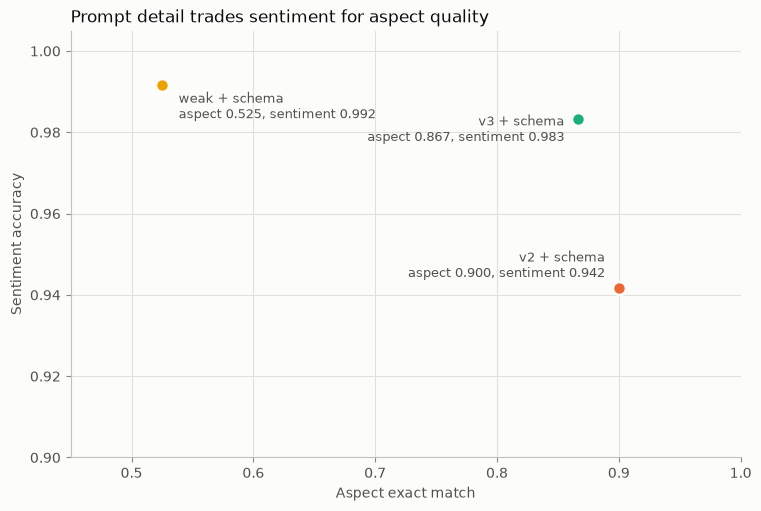

,v2 + schema,weak + schema,v3 + schema
Sentiment accuracy,0.942,0.992,0.983
Aspect exact match,0.900,0.525,0.867
Not grounded (hallucinated) aspects,2.000,52.000,7.000
Joint accuracy,0.842,0.517,0.850


In [5]:
tradeoff_runs = {"v2 + schema": "v2", "weak + schema": "weak + schema", "v3 + schema": "v3 + schema"}
label_offsets = {"v2 + schema": (-10, 8, "right"), "weak + schema": (12, -24, "left"), "v3 + schema": (-10, -16, "right")}

fig, ax = plt.subplots(figsize=(7.5, 5), constrained_layout=True)

for run, color_key in tradeoff_runs.items():
    sentiment = metrics[run]["Sentiment accuracy"]
    aspect = metrics[run]["Aspect exact match"]
    ax.scatter(aspect, sentiment, s=90, color=COLORS[color_key], zorder=3, edgecolors=SURFACE, linewidths=2)
    ax.annotate(f"{run}\naspect {aspect:.3f}, sentiment {sentiment:.3f}", (aspect, sentiment),
                textcoords="offset points", xytext=label_offsets[run][:2], ha=label_offsets[run][2],
                color=INK_SECONDARY, fontsize=9)

ax.set_xlim(0.45, 1.0)
ax.set_ylim(0.90, 1.005)
ax.grid(True)
ax.set_axisbelow(True)
ax.set_xlabel("Aspect exact match")
ax.set_ylabel("Sentiment accuracy")
ax.set_title("Prompt detail trades sentiment for aspect quality", loc="left")
plt.show()

tradeoff_table = pd.DataFrame({
    run: {
        "Sentiment accuracy": metrics[run]["Sentiment accuracy"],
        "Aspect exact match": metrics[run]["Aspect exact match"],
        "Not grounded (hallucinated) aspects": sum(
            not evaluate.is_grounded(evaluate.get_prediction(r)[1], r["text"], case_sensitive=False)
            for r in results[run]),
        "Joint accuracy": metrics[run]["Joint accuracy (sentiment + exact aspect)"],
    }
    for run in tradeoff_runs
}).round(3)
tradeoff_table

**Yorum:**
- **weak** prompt sentiment'te en iyi sonucu veriyor (%99,2), ama aspect'i metinden kopyalamak yerine kategori adı üretiyor (`bagels` → `food`, `waitress` → `service`). Bu yüzden 52 aspect metinde yok.
- **v2** aspect'te en iyisi (%90,0), ama sentiment'te negatif tarafa kayıyor (%94,2).
- **v3** ikisinin arasında: sentiment %98,3, aspect %86,7. Joint accuracy'de v2 ile neredeyse aynı (fark 1 örnek).

## 5. Olumsuzluk ifadelerinin etkisi

Gold etiketi **positive** olan cümleler, olumsuzluk ifadesi (`not`, `never`, `can't`, ...) içerip içermemesine göre ikiye ayrılır.

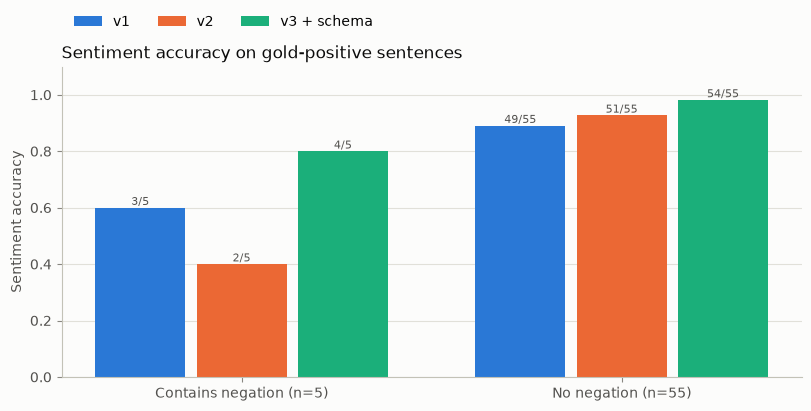

,run,group,correct,total,accuracy
0,v1,with negation,3,5,0.600000
1,v1,without negation,49,55,0.890909
2,v2,with negation,2,5,0.400000
3,v2,without negation,51,55,0.927273
4,v3 + schema,with negation,4,5,0.800000
5,v3 + schema,without negation,54,55,0.981818


In [6]:
negation_runs = ["v1", "v2", "v3 + schema"]
groups = ["with negation", "without negation"]
rows = []

for name in negation_runs:
    positive = [r for r in results[name] if r["gold_sentiment"] == "positive"]

    for group in groups:
        has_negation = group == "with negation"
        subset = [r for r in positive
                  if bool(re.search(evaluate.NEGATION_PATTERN, r["text"], re.IGNORECASE)) == has_negation]
        correct = sum(evaluate.get_prediction(r)[0] == "positive" for r in subset)
        rows.append({"run": name, "group": group, "correct": correct,
                     "total": len(subset), "accuracy": correct / len(subset)})

negation_table = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
series, labels = {}, {}

for name in negation_runs:
    subset = negation_table[negation_table["run"] == name].set_index("group").loc[groups]
    series[name] = subset["accuracy"].tolist()
    labels[name] = [f"{c}/{t}" for c, t in zip(subset["correct"], subset["total"])]

grouped_bars(ax, ["Contains negation (n=5)", "No negation (n=55)"], series, labels)
ax.set_ylim(0, 1.1)
style_bar_axis(ax, "Sentiment accuracy on gold-positive sentences", "Sentiment accuracy")
plt.show()

negation_table

**Yorum:** Ayrıntılı prompt'larda (v1, v2) olumsuzluk ifadesi içeren olumlu cümlelerde doğruluk belirgin şekilde düşüyor (`should not be overlooked`, `cannot imagine a friendlier staff`). v3'te bu düşüş büyük ölçüde kayboluyor. Bu grupta yalnızca 5 cümle olduğu için sonuç bir gözlemdir.

## 6. Yorum uzunluğunun etkisi

Cümleler kelime sayısına göre üç gruba ayrılır: kısa (≤7), orta (8–12), uzun (≥13).

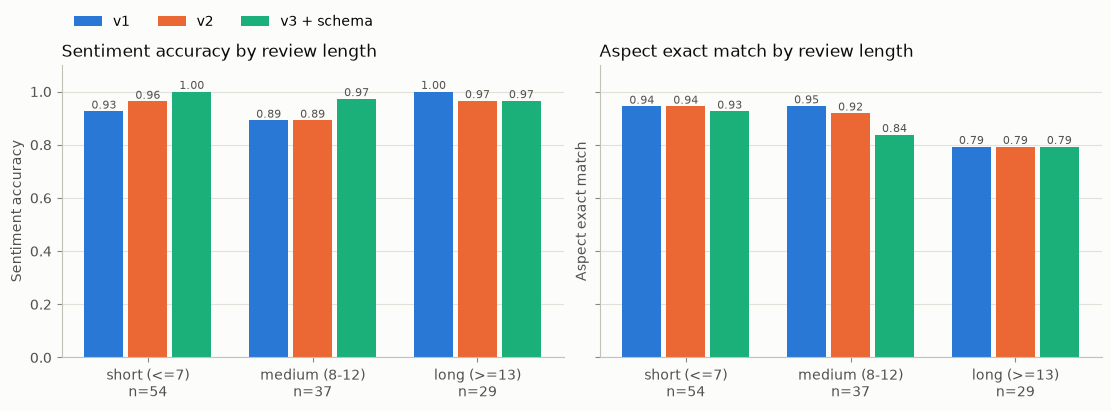

,run,length,n,sentiment accuracy,aspect exact match
0,v1,short (<=7),54,0.926,0.944
1,v1,medium (8-12),37,0.892,0.946
2,v1,long (>=13),29,1.000,0.793
3,v2,short (<=7),54,0.963,0.944
4,v2,medium (8-12),37,0.892,0.919
5,v2,long (>=13),29,0.966,0.793
6,v3 + schema,short (<=7),54,1.000,0.926
7,v3 + schema,medium (8-12),37,0.973,0.838
8,v3 + schema,long (>=13),29,0.966,0.793


In [7]:
length_bins = [("short (<=7)", 0, 7), ("medium (8-12)", 8, 12), ("long (>=13)", 13, 999)]
length_runs = ["v1", "v2", "v3 + schema"]
rows = []

for name in length_runs:
    for bin_name, low, high in length_bins:
        subset = [r for r in results[name] if low <= word_counts[r["id"]] <= high]
        rows.append({
            "run": name,
            "length": bin_name,
            "n": len(subset),
            "sentiment accuracy": sum(evaluate.get_prediction(r)[0] == r["gold_sentiment"] for r in subset) / len(subset),
            "aspect exact match": sum(evaluate.classify_aspect(r) == "exact" for r in subset) / len(subset),
        })

length_table = pd.DataFrame(rows)
bin_labels = [f"{name}\nn={length_table[length_table['length'] == name]['n'].iloc[0]}" for name, _, _ in length_bins]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True, sharey=True)

for ax, metric in zip(axes, ["sentiment accuracy", "aspect exact match"]):
    series = {name: length_table[length_table["run"] == name][metric].tolist() for name in length_runs}
    labels = {name: [f"{v:.2f}" for v in values] for name, values in series.items()}
    grouped_bars(ax, bin_labels, series, labels)
    ax.set_ylim(0, 1.1)
    style_bar_axis(ax, metric.capitalize() + " by review length", metric.capitalize())

axes[1].get_legend().remove()
plt.show()

length_table.round(3)

**Yorum:** Sentiment başarısı uzunluktan etkilenmiyor. Aspect başarısı ise uzun yorumlarda üç sürümde de %79'a düşüyor: uzun cümlelerde daha fazla aday isim var ve model ya yanlış olanı seçiyor (`restaurant`) ya da çok kelimeli aspect'i kısaltıyor (`half price sushi deal` → `sushi`).

## 7. Sentiment ve aspect hataları aynı yorumda mı?

In [8]:
rows = []

for name in ["v1", "v2", "v3 + schema"]:
    counts = {"both correct": 0, "only aspect wrong": 0, "only sentiment wrong": 0, "both wrong": 0}

    for record in results[name]:
        sentiment_ok = evaluate.get_prediction(record)[0] == record["gold_sentiment"]
        aspect_ok = evaluate.classify_aspect(record) == "exact"

        if sentiment_ok and aspect_ok:
            counts["both correct"] += 1
        elif sentiment_ok:
            counts["only aspect wrong"] += 1
        elif aspect_ok:
            counts["only sentiment wrong"] += 1
        else:
            counts["both wrong"] += 1

    rows.append({"run": name, **counts})

pd.DataFrame(rows).set_index("run")

,both correct,only aspect wrong,only sentiment wrong,both wrong
run,,,,
v1,102,10,7,1
v2,101,12,7,0
v3 + schema,102,16,2,0


**Yorum:** İki görevin hataları neredeyse hiç çakışmıyor (v1'de 1 örnek, v2 ve v3'te 0). Model aspect'i yanlış bulduğunda bile sentiment'i çoğunlukla doğru tahmin ediyor. Hatalar "cümleyi hiç anlamamış" türünden değil, her görevin kendi zayıflığından geliyor.

## 8. Aspect hata türleri

- **span too short:** aspect kısaltılmış (`crispy chicken` → `chicken`)
- **span too long:** fazladan kelime eklenmiş (`wine` → `Free wine`)
- **wrong target:** başka bir şey seçilmiş (`people` → `restaurant`)

weak prompt'un 44–45 "wrong target" hatası ölçeği bozduğu için bu grafikte yer almıyor, değeri tabloda.

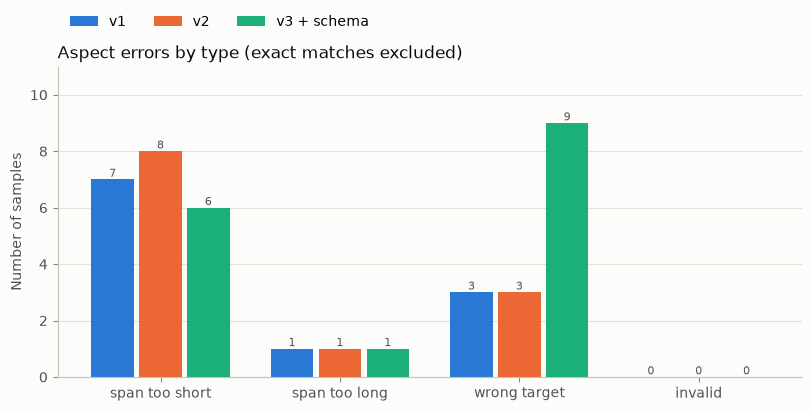

,v1,v2,v2 + schema,weak,weak + schema,v3 + schema
exact,109,108,108,63,63,104
span too short,7,8,8,5,6,6
span too long,1,1,1,8,6,1
wrong target,3,3,3,44,45,9
invalid,0,0,0,0,0,0


In [9]:
error_types = ["span too short", "span too long", "wrong target", "invalid"]

error_counts = pd.DataFrame({
    name: pd.Series([evaluate.classify_aspect(r) for r in records]).value_counts()
    for name, records in results.items()
}).reindex(["exact"] + error_types).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
error_runs = ["v1", "v2", "v3 + schema"]
grouped_bars(ax, error_types, {name: error_counts.loc[error_types, name].tolist() for name in error_runs})
ax.set_ylim(0, error_counts.loc[error_types, error_runs].to_numpy().max() + 2)
style_bar_axis(ax, "Aspect errors by type (exact matches excluded)", "Number of samples")
plt.show()

error_counts

**Yorum:** Ayrıntılı prompt'larda (v1, v2) en sık hata çok kelimeli aspect'lerin kısaltılması. v3'te "wrong target" artıyor (3 → 9), çünkü kısa prompt'un kategori adı üretme eğilimi kısmen geri dönüyor.

## 9. İroni içeren örnekler

Veri temizliğinde ironi içerdiği için elenen 8 örnek (`data/excluded_samples.json`, `reason = sarcasm`) v2 ve v3'e gönderilir. Bu hücre modeli canlı olarak çağırır, bu yüzden **Ollama'nın açık olması gerekir**. `temperature 0` olduğu için sonuçlar her çalıştırmada aynıdır.

In [10]:
from model import generate_response
from parser import parse_response

sarcasm_samples = [r for r in evaluate.load_results("data/excluded_samples.json") if r["reason"] == "sarcasm"]
rows = []

for sample in sarcasm_samples:
    row = {"text": sample["text"], "gold": sample["gold_sentiment"]}

    for label, model_name, use_schema in [("v2", "absa-model-v2", False), ("v3 + schema", "absa-model-v3", True)]:
        parsed, _, _ = parse_response(generate_response(sample["text"], model_name, use_schema))
        row[label] = parsed["sentiment"] if isinstance(parsed, dict) else None

    rows.append(row)

sarcasm_table = pd.DataFrame(rows)
print("v2 correct:", (sarcasm_table["v2"] == sarcasm_table["gold"]).sum(), "/", len(sarcasm_table))
print("v3 correct:", (sarcasm_table["v3 + schema"] == sarcasm_table["gold"]).sum(), "/", len(sarcasm_table))

pd.set_option("display.max_colwidth", None)
sarcasm_table

v2 correct: 6 / 8
v3 correct: 6 / 8


,text,gold,v2,v3 + schema
0,Nothing better than buying a snapple for $3.25 too.,positive,negative,negative
1,Here's to the fake fish tanks too...,negative,negative,negative
2,"Oh, but wait, we were out of drinks (which were also delightfully overpriced).",negative,negative,negative
3,They pray to their Food Gods to make them into a good pizza like VT's.,negative,positive,positive
4,Good luck getting a table.,negative,negative,negative
5,Tell them Herky sent you and get a free confused look from the waiter.,negative,negative,negative
6,I've lived in NYC all my life and had never before seen so many waterbugs in one place (except in a really bad dream).,negative,negative,negative
7,DO not try unless you're just going there to hang out like the rest of the hipsters who apparently have no sense of taste.,negative,negative,negative


**Yorum:** İki sürüm de 6/8 doğru. Ancak doğru tahminlerin çoğunda açık olumsuz bir ifade var (`fake`, `overpriced`, `confused`, `really bad dream`, `no sense of taste`). Olumsuz kelime içermeyen tek doğru örnek "Good luck getting a table." Olumlu kelimeyle kurulmuş ironide ("a good pizza like VT's") model düz anlamı seçiyor. "Nothing better than buying a snapple for $3.25" örneğinde ise gold etiket (`positive`) cümleyi düz anlamıyla okuyor, model `negative` diyor, yani etiketin kendisi tartışmalı. Örneklem çok küçük, bu sonuçlar modelin ironiyi anladığına dair güçlü bir kanıt sunmuyor.

## 10. Nicemleme (quantization): Q4 ve Q8

Aynı v2 prompt'u iki farklı nicemleme seviyesiyle çalıştırıldı. Q4'te ağırlıklar yaklaşık 4 bit, Q8'de 8 bit ile saklanıyor. Süre ölçümü her çalıştırmada bir ısınma (warm-up) isteğinden sonra başladı, böylece modelin belleğe yüklenme süresi ölçüme dahil olmadı.

Bellek değerleri çalıştırmalar sırasında `ollama ps` komutuyla ölçüldü (Apple M4, modeller %100 GPU'da). Dosya boyutları `ollama list` çıktısından alındı.

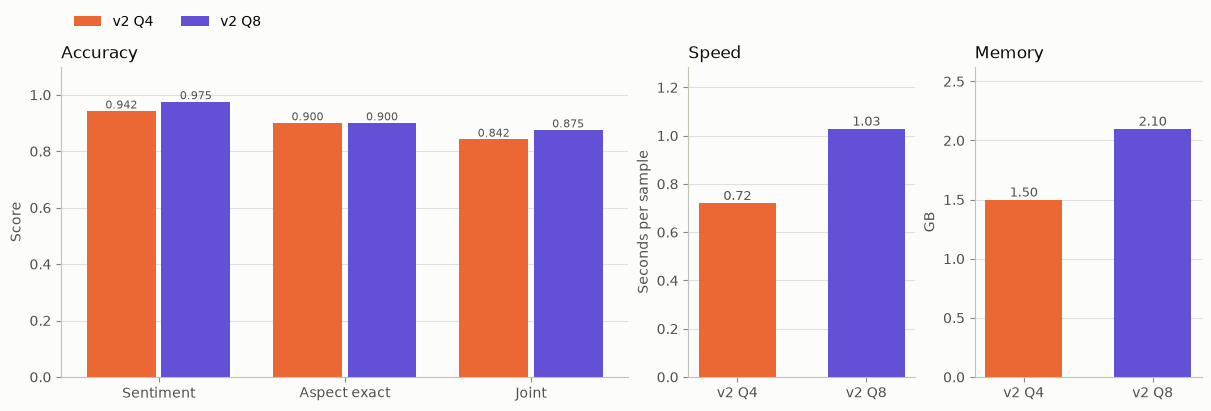

,v2 Q4,v2 Q8
Sentiment accuracy,0.942,0.975
Aspect exact match,0.900,0.900
Joint accuracy,0.842,0.875
JSON first-try success,1.000,1.000
Avg seconds per sample,0.721,1.029
Memory in use (GB),1.500,2.100
Model file (GB),1.400,2.200


In [11]:
quant_results = {
    "v2 Q4": evaluate.load_results("results/test/results_v2_q4_timed.json"),
    "v2 Q8": evaluate.load_results("results/test/results_v2_q8.json"),
}
quant_metrics = {name: evaluate.evaluate(records) for name, records in quant_results.items()}

# ollama ps ve ollama list ile ölçülen değerler (GB)
MEMORY_GB = {"v2 Q4": 1.5, "v2 Q8": 2.1}
FILE_SIZE_GB = {"v2 Q4": 1.4, "v2 Q8": 2.2}

quant_table = pd.DataFrame({
    name: {
        "Sentiment accuracy": quant_metrics[name]["Sentiment accuracy"],
        "Aspect exact match": quant_metrics[name]["Aspect exact match"],
        "Joint accuracy": quant_metrics[name]["Joint accuracy (sentiment + exact aspect)"],
        "JSON first-try success": quant_metrics[name]["JSON first-try success"],
        "Avg seconds per sample": quant_metrics[name]["Avg seconds per sample"],
        "Memory in use (GB)": MEMORY_GB[name],
        "Model file (GB)": FILE_SIZE_GB[name],
    }
    for name in quant_results
}).round(3)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True,
                         gridspec_kw={"width_ratios": [3, 1.2, 1.2]})

accuracy_metrics = ["Sentiment accuracy", "Aspect exact match", "Joint accuracy"]
series = {name: quant_table.loc[accuracy_metrics, name].tolist() for name in quant_results}
grouped_bars(axes[0], ["Sentiment", "Aspect exact", "Joint"], series,
             {name: [f"{v:.3f}" for v in values] for name, values in series.items()})
axes[0].set_ylim(0, 1.1)
style_bar_axis(axes[0], "Accuracy", "Score")

for ax, row, title, unit in [(axes[1], "Avg seconds per sample", "Speed", "Seconds per sample"),
                              (axes[2], "Memory in use (GB)", "Memory", "GB")]:
    values = quant_table.loc[row, list(quant_results)]
    bars = ax.bar(list(quant_results), values, 0.6,
                  color=[COLORS[name] for name in quant_results])
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.2f}",
                ha="center", va="bottom", color=INK_SECONDARY, fontsize=9)
    ax.set_ylim(0, values.max() * 1.25)
    style_bar_axis(ax, title, unit)

plt.show()

quant_table

In [12]:
# Q4 ile Q8'in sentiment tahmininin farklı olduğu örnekler
q4 = {r["id"]: r for r in quant_results["v2 Q4"]}
q8 = {r["id"]: r for r in quant_results["v2 Q8"]}

rows = []
for sample_id, record in q4.items():
    q4_sentiment = evaluate.get_prediction(record)[0]
    q8_sentiment = evaluate.get_prediction(q8[sample_id])[0]
    if q4_sentiment != q8_sentiment:
        rows.append({"id": sample_id, "gold": record["gold_sentiment"], "Q4": q4_sentiment,
                     "Q8": q8_sentiment, "text": record["text"]})

pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows)

,id,gold,Q4,Q8,text
0,19,positive,positive,negative,"Sure, the setting is nice."
1,66,positive,negative,positive,The atmosphere is much better than Sripraphai (more modern and sleek).
2,75,positive,negative,positive,All the desserts the group tried got favorable reviews.
3,80,positive,negative,positive,The sake menu should not be overlooked!
4,101,positive,negative,positive,"I can't wait for summer, when they serve outside on their gigantic patio."
5,104,positive,negative,positive,I cannot imagine a friendlier staff working in a restaurant.


**Yorum:**
- Q8 sentiment'te net 4 örnek daha iyi (%94,2 → %97,5): 5 örneği düzeltiyor, 1 örneği (#19 "Sure, the setting is nice.") bozuyor. Aspect'te hiç fark yok (%90,0). Nicemleme sentiment'i etkiliyor, aspect çıkarmayı etkilemiyor.
- Q8'in düzelttiği örneklerin çoğu olumsuzluk veya karşılaştırma içeriyor. Bunların arasında düşünme modunun bile düzeltemediği #104 ("I cannot imagine a friendlier staff…") de var.
- Bedeli: Q8 yaklaşık %40 daha fazla bellek kullanıyor ve örnek başına %43 daha yavaş.
- Q4'teki negatif eğilimin bir kısmı nicemleme kaybından kaynaklanıyor olabilir.

## 11. Temperature: örnekleme rastgeleliğinin etkisi

v2 (Q4) her temperature değerinde 3 farklı seed ile çalıştırıldı. Grafikteki noktalar 3 çalıştırmanın ortalaması, dikey çizgiler ± 1 standart sapma. Temperature 0 deterministik olduğu için tek çalıştırma kullanıldı (aynı ayarla yapılan iki ayrı çalıştırmada 120 tahminin 120'si aynı çıktı).

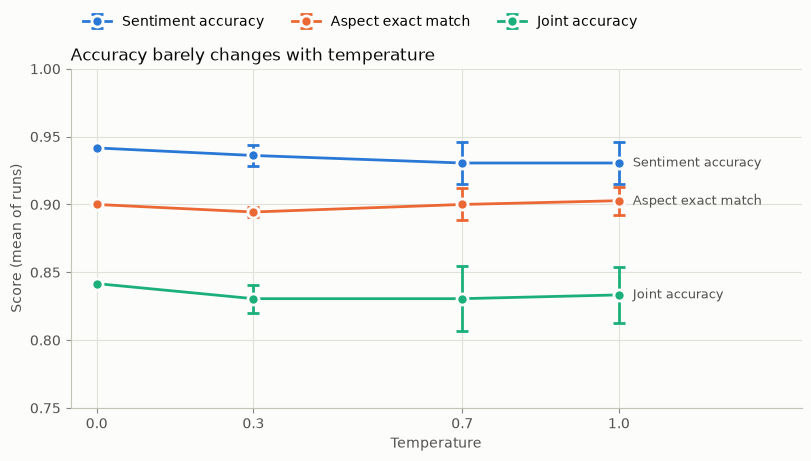

,temperature,runs,Sentiment accuracy,Sentiment accuracy std,Aspect exact match,Aspect exact match std,Joint accuracy,Joint accuracy std,JSON first-try success,Samples with unstable sentiment
0,0.0,1,0.942,0.000,0.900,0.000,0.842,0.000,1.0,0
1,0.3,3,0.936,0.008,0.894,0.004,0.831,0.010,1.0,2
2,0.7,3,0.931,0.016,0.900,0.012,0.831,0.024,1.0,4
3,1.0,3,0.931,0.016,0.903,0.010,0.833,0.020,1.0,4


In [13]:
TEMPERATURES = [0.0, 0.3, 0.7, 1.0]
SEEDS = [1, 2, 3]

temperature_runs = {0.0: [evaluate.load_results("results/test/results_v2_q4_timed.json")]}
for t in TEMPERATURES[1:]:
    temperature_runs[t] = [evaluate.load_results(f"results/test/results_v2_temp{t}_seed{s}.json") for s in SEEDS]

temperature_metrics = {
    "Sentiment accuracy": "Sentiment accuracy",
    "Aspect exact match": "Aspect exact match",
    "Joint accuracy": "Joint accuracy (sentiment + exact aspect)",
}

rows = []
for t, runs in temperature_runs.items():
    run_metrics = [evaluate.evaluate(records) for records in runs]
    row = {"temperature": t, "runs": len(runs)}

    for label, key in temperature_metrics.items():
        values = [m[key] for m in run_metrics]
        row[label] = np.mean(values)
        row[label + " std"] = np.std(values)

    row["JSON first-try success"] = np.mean([m["JSON first-try success"] for m in run_metrics])

    # Seed'ler arasında sentiment cevabı değişen örnek sayısı
    by_id = [{r["id"]: r for r in records} for records in runs]
    row["Samples with unstable sentiment"] = sum(
        len({evaluate.get_prediction(run[i])[0] for run in by_id}) > 1 for i in by_id[0])

    rows.append(row)

temperature_table = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
line_colors = {"Sentiment accuracy": "#2a78d6", "Aspect exact match": "#eb6834", "Joint accuracy": "#1baf7a"}

for label, color in line_colors.items():
    ax.errorbar(temperature_table["temperature"], temperature_table[label],
                yerr=temperature_table[label + " std"], color=color, linewidth=2,
                marker="o", markersize=8, markeredgecolor=SURFACE, markeredgewidth=2,
                capsize=4, label=label)
    last = temperature_table.iloc[-1]
    ax.annotate(label, (last["temperature"], last[label]), textcoords="offset points",
                xytext=(10, 0), va="center", color=INK_SECONDARY, fontsize=9)

ax.set_xticks(TEMPERATURES)
ax.set_xlim(-0.05, 1.35)
ax.set_ylim(0.75, 1.0)
ax.grid(True)
ax.set_axisbelow(True)
ax.set_xlabel("Temperature")
ax.set_ylabel("Score (mean of runs)")
ax.set_title("Accuracy barely changes with temperature", loc="left")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=3)
plt.show()

temperature_table.round(3)

**Yorum:**
- **JSON formatı rastgelelikten hiç etkilenmiyor:** temperature 1,0'da bile 9 çalıştırmanın hepsinde 120/120 ilk denemede geçerli JSON var.
- **Doğruluk çok az düşüyor:** ortalama sentiment %94,2'den yaklaşık %93,1'e iniyor. Bu düşüş standart sapmanın içinde, yani anlamlı değil. Aspect değişmiyor.
- **Kararsızlık sınırlı:** temperature arttıkça seed'e göre farklı cevap alan örnek sayısı artıyor, ama 120 örneğin en fazla 4'ü.
- Temperature 0 hem en iyi hem de tamamen tekrarlanabilir sonucu veriyor. Ana deneylerde kullanılması doğru bir seçim.

## 12. Qwen3 düşünme modu (`think`)

Qwen3, cevap vermeden önce akıl yürütebilen (reasoning) bir model. Düşünme modu açıldığında model önce bir düşünme metni üretiyor, sonra cevabı veriyor. Düşünme metni de token sınırına dahil olduğu için bu deneyde `num_predict` 2048'e çıkarıldı.

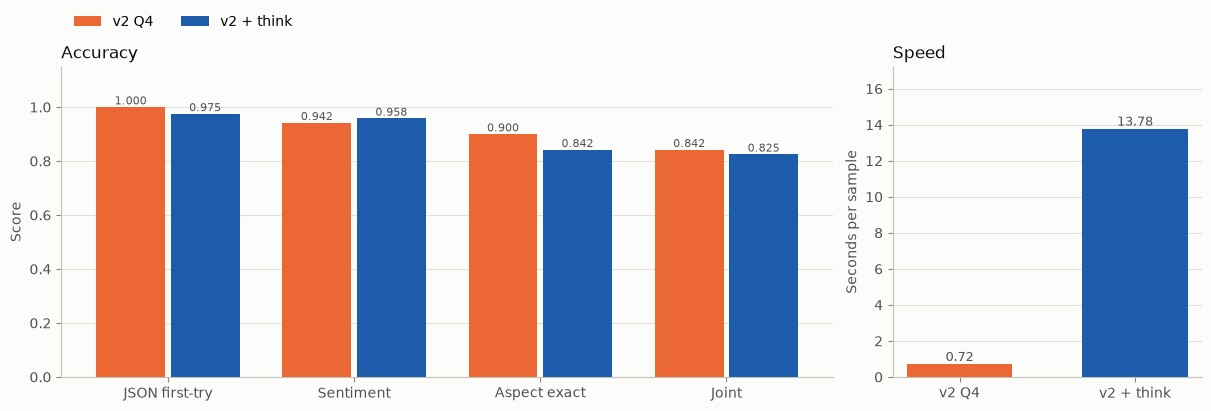

,v2 Q4,v2 + think
JSON first-try success,1.000,0.975
Sentiment accuracy,0.942,0.958
Aspect exact match,0.900,0.842
Joint accuracy,0.842,0.825
Avg seconds per sample,0.721,13.780
Max seconds per sample,0.879,74.526
Empty responses,0.000,3.000


In [14]:
think_results = {
    "v2 Q4": evaluate.load_results("results/test/results_v2_q4_timed.json"),
    "v2 + think": evaluate.load_results("results/test/results_v2_think.json"),
}
think_metrics = {name: evaluate.evaluate(records) for name, records in think_results.items()}

think_table = pd.DataFrame({
    name: {
        "JSON first-try success": think_metrics[name]["JSON first-try success"],
        "Sentiment accuracy": think_metrics[name]["Sentiment accuracy"],
        "Aspect exact match": think_metrics[name]["Aspect exact match"],
        "Joint accuracy": think_metrics[name]["Joint accuracy (sentiment + exact aspect)"],
        "Avg seconds per sample": think_metrics[name]["Avg seconds per sample"],
        "Max seconds per sample": max(r["duration_seconds"] for r in think_results[name]),
        "Empty responses": sum(r["raw_response"].strip() == "" for r in think_results[name]),
    }
    for name in think_results
}).round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True,
                         gridspec_kw={"width_ratios": [3, 1.2]})

accuracy_metrics = ["JSON first-try success", "Sentiment accuracy", "Aspect exact match", "Joint accuracy"]
series = {name: think_table.loc[accuracy_metrics, name].tolist() for name in think_results}
grouped_bars(axes[0], ["JSON first-try", "Sentiment", "Aspect exact", "Joint"], series,
             {name: [f"{v:.3f}" for v in values] for name, values in series.items()})
axes[0].set_ylim(0, 1.15)
style_bar_axis(axes[0], "Accuracy", "Score")

values = think_table.loc["Avg seconds per sample", list(think_results)]
bars = axes[1].bar(list(think_results), values, 0.6, color=[COLORS[name] for name in think_results])
for bar, value in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value, f"{value:.2f}",
                 ha="center", va="bottom", color=INK_SECONDARY, fontsize=9)
axes[1].set_ylim(0, values.max() * 1.25)
style_bar_axis(axes[1], "Speed", "Seconds per sample")

plt.show()

think_table

In [15]:
# Düşünme modunun sentiment tahminini değiştirdiği örnekler
base = {r["id"]: r for r in think_results["v2 Q4"]}
think = {r["id"]: r for r in think_results["v2 + think"]}

rows = []
for sample_id, record in base.items():
    gold = record["gold_sentiment"]
    before = evaluate.get_prediction(record)[0]
    after = evaluate.get_prediction(think[sample_id])[0]

    if (before == gold) != (after == gold):
        rows.append({"id": sample_id, "gold": gold, "think off": before, "think on": after,
                     "change": "fixed" if after == gold else "broken", "text": record["text"]})

pd.DataFrame(rows).sort_values("change")

,id,gold,think off,think on,change,text
0,54,negative,negative,positive,broken,A bit breezy up there on the mezzanine from the wind coming from the tracks.
2,64,positive,positive,NaN,broken,"I have had so many dinners here and it's always been perfect - on a date with my husband, with my mom, with girlfriends and larger groups."
6,84,positive,positive,NaN,broken,"This is such a lovely, peaceful place to eat outside."
8,106,negative,negative,NaN,broken,It was like the servers forgot that they actually worked there and instead wanted to hang out and be cool.
1,63,positive,negative,positive,fixed,we decided to eat in tea room which was small and cute.
3,66,positive,negative,positive,fixed,The atmosphere is much better than Sripraphai (more modern and sleek).
4,75,positive,negative,positive,fixed,All the desserts the group tried got favorable reviews.
5,80,positive,negative,positive,fixed,The sake menu should not be overlooked!
7,101,positive,negative,positive,fixed,"I can't wait for summer, when they serve outside on their gigantic patio."
9,115,positive,negative,positive,fixed,The price very reasonable.


In [16]:
# Düşünme moduna rağmen yanlış kalan örnek: modelin kendi akıl yürütmesi
example = think[104]
print(example["text"])
print("Gold:", example["gold_sentiment"], "| Prediction:", evaluate.get_prediction(example)[0])
print()
print("...", example["thinking"][-650:])

I cannot imagine a friendlier staff working in a restaurant.
Gold: positive | Prediction: negative

... t. So the aspect here is "staff."

Now the sentiment. The reviewer says "I cannot imagine a friendlier staff working in a restaurant." The sentiment here is negative because they're expressing that the staff is not friendly. The sentiment label should be negative. So the sentiment is negative, aspect is staff.

Wait, but the example given in the output format had "pizza" as the aspect. So in this case, the aspect is "staff." But I need to make sure that the aspect is exactly a substring. The original sentence has "staff" as a substring. So that's correct. The sentiment is negative because the reviewer is criticizing the staff's friendliness.



**Yorum:**
- **Sentiment iyileşiyor:** v2'nin 7 sentiment hatasından 6'sı düzeliyor (`should not be overlooked`, `can't wait for summer`, `much better than` gibi). Akıl yürütme olumsuzluk ve karşılaştırma içeren cümlelerde yardımcı oluyor.
- **Düzelmeyen örnek modelin dil anlayışındaki sınırı gösteriyor:** #104'te model kendi düşünme metninde "cannot imagine a friendlier staff" ifadesini açıkça "personel samimi değil" diye yorumluyor. Hata dikkatsizlikten değil, ifadenin yanlış anlaşılmasından kaynaklanıyor.
- **Aspect kötüleşiyor:** Model düşünürken prompt'taki "the service" örneğine takılıp terimleri kategoriye çeviriyor (`hostess`, `server`, `waitstaff` → `service`).
- **3 boş cevap:** Model 2048 token'ın tamamını düşünmeye harcayıp cevap üretemiyor. Parser'ın da kurtaramayacağı bir hata türü bu: ayrıştırılacak metin yok. "Sentiment değişen örnekler" tablosundaki "broken" satırlarının üçü bu boş cevaplar.
- **Çok yavaş:** Örnek başına ortalama 13,8 saniye (düşünme modu kapalıyken 0,72 saniye), en uzunu 74,5 saniye.
- Bu görev için düşünme modu kapalı **Q8** daha iyi bir seçim: sentiment'i benzer ölçüde iyileştiriyor, aspect'i bozmuyor ve yalnızca %43 daha yavaş.

## 13. Dev setinde iyileştirme yöntemlerinin karşılaştırılması

1–12. bölümlerdeki deneylerin bir kısmı (weak, v3) test setinin sonuçlarına bakılarak tasarlandı. Test setine göre ayar yapmamak için iyileştirme yöntemleri **ayrı bir dev setinde** (80 örnek, test setiyle ortak cümle yok) karşılaştırıldı ve yalnızca kazanan yöntem test setinde bir kez çalıştırıldı.

| Yöntem | Açıklama |
|---|---|
| **v2** | Başlangıç noktası (baseline) |
| **v2 Q8** | Aynı prompt, `qwen3:1.7b-q8_0` |
| **Few-shot** | v2 + 5 uydurma örnek (olumsuzluk ifadeli olumlu cümleler, çok kelimeli aspect, `waiter`) |
| **Reason (gerekçe alanı)** | v2 + JSON'da sentiment'ten önce tek cümlelik `reason` alanı (aspect → reason → sentiment) |
| **Pipeline (iki aşamalı)** | 1. çağrı yalnızca aspect'i çıkarır, 2. çağrı kısa bir prompt'la o aspect'e yönelik duyguyu belirler |

Grafikte seçilen yöntem yeşil, diğerleri gri gösterilir.

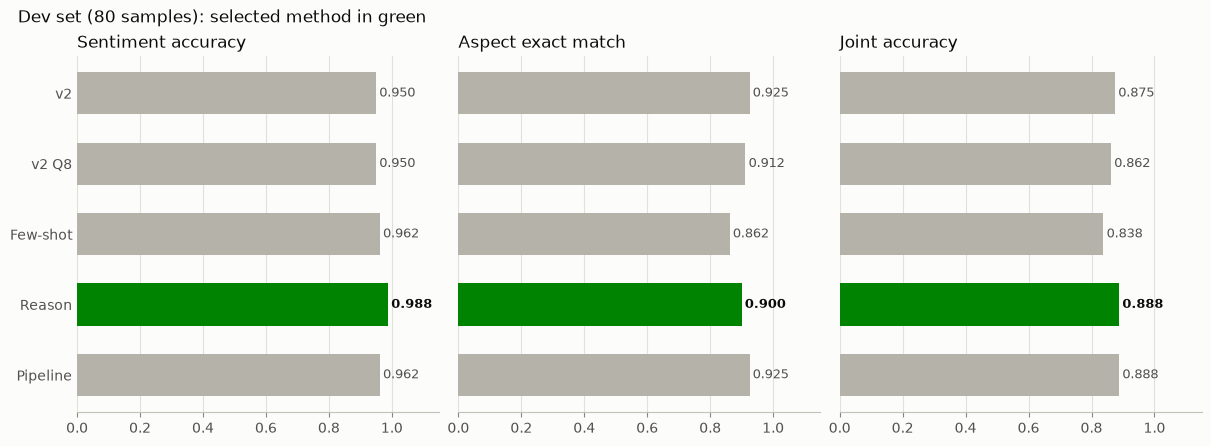

,v2,v2 Q8,Few-shot,Reason,Pipeline
Sentiment accuracy,0.950,0.950,0.962,0.988,0.962
Aspect exact match,0.925,0.912,0.862,0.900,0.925
Joint accuracy,0.875,0.862,0.838,0.888,0.888
JSON first-try success,1.000,1.000,1.000,1.000,1.000
Avg seconds per sample,0.712,1.112,0.611,1.373,0.875


In [17]:
SELECTED_COLOR = "#008300"
OTHER_COLOR = "#b4b2a9"

dev_files = {
    "v2": "results/dev/dev_results_v2.json",
    "v2 Q8": "results/dev/dev_results_v2_q8.json",
    "Few-shot": "results/dev/dev_results_fewshot.json",
    "Reason": "results/dev/dev_results_reason.json",
    "Pipeline": "results/dev/dev_results_pipeline.json",
}
dev_results = {name: evaluate.load_results(path) for name, path in dev_files.items()}
dev_metrics = {name: evaluate.evaluate(records) for name, records in dev_results.items()}

dev_table = pd.DataFrame({
    name: {
        "Sentiment accuracy": dev_metrics[name]["Sentiment accuracy"],
        "Aspect exact match": dev_metrics[name]["Aspect exact match"],
        "Joint accuracy": dev_metrics[name]["Joint accuracy (sentiment + exact aspect)"],
        "JSON first-try success": dev_metrics[name]["JSON first-try success"],
        "Avg seconds per sample": dev_metrics[name]["Avg seconds per sample"],
    }
    for name in dev_files
}).round(3)


def highlight_panels(table, methods, selected, title):
    # Her metrik için ayrı panel: yöntemler eksende, seçilen yöntem vurgulu
    panel_metrics = ["Sentiment accuracy", "Aspect exact match", "Joint accuracy"]
    fig, axes = plt.subplots(1, 3, figsize=(12, 0.55 * len(methods) + 1.6),
                             constrained_layout=True, sharey=True)
    y = np.arange(len(methods))[::-1]

    for ax, metric in zip(axes, panel_metrics):
        values = [table.loc[metric, m] for m in methods]
        colors = [SELECTED_COLOR if m == selected else OTHER_COLOR for m in methods]
        ax.barh(y, values, color=colors, height=0.6)
        for yi, value, method in zip(y, values, methods):
            ax.text(value + 0.01, yi, f"{value:.3f}", va="center", fontsize=9,
                    color=INK if method == selected else INK_SECONDARY,
                    fontweight="bold" if method == selected else "normal")
        ax.set_xlim(0, 1.15)
        ax.set_yticks(y, methods)
        ax.xaxis.grid(True)
        ax.set_axisbelow(True)
        ax.tick_params(axis="y", length=0)
        ax.spines["left"].set_visible(False)
        ax.set_title(metric, loc="left")

    fig.suptitle(title, color=INK, x=0.01, ha="left")
    plt.show()


highlight_panels(dev_table, list(dev_files), "Reason", "Dev set (80 samples): selected method in green")
dev_table

**Yorum:**
- **Reason** ve **Pipeline** joint accuracy'de berabere (%88,8, 80'de 71). Reason sentiment'te (%98,8), Pipeline aspect'te (%92,5) daha iyi.
- Eşitlik durumunda **daha sade olan** seçildi: Reason tek çağrı yapıyor ve mevcut `run.py` ile çalışıyor (`--schema --reason`). Pipeline iki model, iki çağrı ve ayrı bir betik gerektiriyor. Reason'ın ek faydası her tahminin yanında modelin gerekçesinin bulunması (yorumlanabilirlik).
- **Few-shot** aspect'i bozdu (%92,5 → %86,3): model örneklerdeki kelimeleri kopyaladı (`price` yerine `prices`).
- **Q8** dev setinde iyileşme göstermedi. Test setindeki kazanç (10. bölüm) genellenmedi.

## 14. Nihai sonuç: test seti

Dev setinde seçilen **Reason** yöntemi test setinde **yalnızca bir kez** çalıştırıldı ve sonuca göre hiçbir değişiklik yapılmadı.

Not: Yöntem dev setinde seçildi, ama yöntemin fikri (olumsuzluk hatalarını hedeflemek) test setinin hata analizinden doğdu. Dev setinde de aynı hata türünün görülmesi ve yöntemin orada da işe yaraması bu etkiyi azaltıyor.

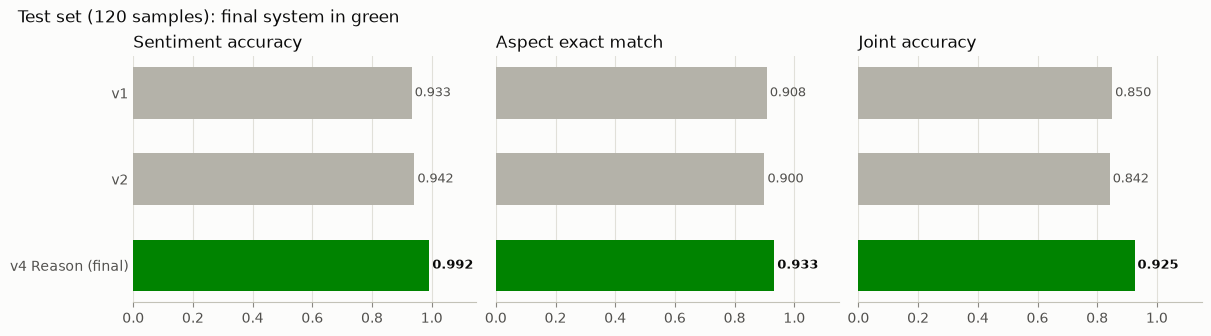

,v1,v2,v4 Reason (final)
Sentiment accuracy,0.933,0.942,0.992
Sentiment macro F1,0.933,0.941,0.992
Aspect exact match,0.908,0.900,0.933
Aspect partial match,0.975,0.975,0.975
Joint accuracy,0.850,0.842,0.925
JSON first-try success,1.000,1.000,1.000
Avg seconds per sample,NaN,NaN,1.403


In [18]:
final_files = {
    "v1": "results/test/results_v1.json",
    "v2": "results/test/results_v2.json",
    "v4 Reason (final)": "results/test/results_v4_reason.json",
}
final_results = {name: evaluate.load_results(path) for name, path in final_files.items()}
final_metrics = {name: evaluate.evaluate(records) for name, records in final_results.items()}

final_table = pd.DataFrame({
    name: {
        "Sentiment accuracy": final_metrics[name]["Sentiment accuracy"],
        "Sentiment macro F1": final_metrics[name]["Sentiment macro F1"],
        "Aspect exact match": final_metrics[name]["Aspect exact match"],
        "Aspect partial match": final_metrics[name]["Aspect partial match"],
        "Joint accuracy": final_metrics[name]["Joint accuracy (sentiment + exact aspect)"],
        "JSON first-try success": final_metrics[name]["JSON first-try success"],
        "Avg seconds per sample": final_metrics[name]["Avg seconds per sample"],
    }
    for name in final_files
}).round(3)

highlight_panels(final_table, list(final_files), "v4 Reason (final)", "Test set (120 samples): final system in green")
final_table

In [19]:
# v2 ile nihai sistemin sentiment veya aspect tahmininin farklı olduğu örnekler ve modelin gerekçesi
v2_by_id = {r["id"]: r for r in final_results["v2"]}
final_by_id = {r["id"]: r for r in final_results["v4 Reason (final)"]}

rows = []
for sample_id, record in v2_by_id.items():
    final_record = final_by_id[sample_id]
    v2_sentiment, v2_aspect = evaluate.get_prediction(record)
    final_sentiment, final_aspect = evaluate.get_prediction(final_record)

    sentiment_change = (v2_sentiment == record["gold_sentiment"]) != (final_sentiment == record["gold_sentiment"])
    aspect_change = (evaluate.classify_aspect(record) == "exact") != (evaluate.classify_aspect(final_record) == "exact")

    if sentiment_change or aspect_change:
        final_correct = (final_sentiment == record["gold_sentiment"]
                         and evaluate.classify_aspect(final_record) == "exact")
        rows.append({
            "id": sample_id,
            "change": "fixed" if final_correct else "broken",
            "gold": f"{record['gold_sentiment']} / {record['gold_aspect']}",
            "v2": f"{v2_sentiment} / {v2_aspect}",
            "final": f"{final_sentiment} / {final_aspect}",
            "reason (model)": final_record["parsed_response"].get("reason", ""),
            "text": record["text"],
        })

changes = pd.DataFrame(rows).sort_values(["change", "id"])
print("fixed:", (changes["change"] == "fixed").sum(), "| broken:", (changes["change"] == "broken").sum())
changes

fixed: 11 | broken: 1


,id,change,gold,v2,final,reason (model),text
0,47,broken,positive / wait,positive / wait,negative / wait,The reviewer says they had a short wait despite being worried about getting in.,"We were worried we would have trouble getting in, but somehow managed to have a short wait."
1,57,fixed,negative / crispy chicken,negative / chicken,negative / crispy chicken,The reviewer says the crispy chicken wasn't for them.,"The crispy chicken wasn't for us, though."
2,63,fixed,positive / tea room,negative / tea room,positive / tea room,"The reviewer mentions the tea room is small and cute, indicating a positive impression.",we decided to eat in tea room which was small and cute.
3,65,fixed,positive / dinner menu,positive / menu,positive / dinner menu,The reviewer says the dinner menu is diverse and top-notch as well.,The dinner menu is diverse and top-notch as well.
4,66,fixed,positive / atmosphere,negative / atmosphere,positive / atmosphere,The reviewer says the atmosphere is much better than Sripraphai (more modern and sleek).,The atmosphere is much better than Sripraphai (more modern and sleek).
5,75,fixed,positive / desserts,negative / desserts,positive / desserts,The reviewer mentions that the desserts the group tried received favorable reviews.,All the desserts the group tried got favorable reviews.
6,80,fixed,positive / sake menu,negative / sake menu,positive / sake menu,The reviewer mentions the sake menu and suggests it should not be overlooked.,The sake menu should not be overlooked!
7,87,fixed,negative / grilled branzino,negative / branzino,negative / grilled branzino,"The reviewer says the grilled branzino was so infused with bone, it was difficult to eat.","We ordered the special, grilled branzino, that was so infused with bone, it was difficult to eat."
8,101,fixed,positive / patio,negative / patio,positive / patio,The reviewer mentions the patio as a feature they look forward to during summer.,"I can't wait for summer, when they serve outside on their gigantic patio."
9,104,fixed,positive / staff,negative / staff,positive / staff,The reviewer says the staff is friendly and welcoming.,I cannot imagine a friendlier staff working in a restaurant.


**Yorum:**
- **Sentiment:** v2'nin 7 hatasının 7'si de düzeldi. Bunların arasında hiçbir önceki yöntemin (düşünme modu dahil) düzeltemediği #104 ("I cannot imagine a friendlier staff…") de var. Yeni hata yalnızca 1 tane (#47). O örnekte modelin gerekçesi doğru ("had a short wait despite being worried"), ama sentiment yine de negatif.
- **Aspect:** 4 kısaltma hatası düzeldi (`crispy chicken`, `dinner menu`, `grilled branzino`, `meat patties in steamed buns`), hiçbir örnek bozulmadı.
- **Joint accuracy:** %84,2 → %92,5 (+10 örnek).
- **Bedeli:** Örnek başına süre yaklaşık iki katına çıktı (0,72 → 1,40 saniye), çünkü gerekçe için ek token üretiliyor.
- Test sonucu dev sonucundan iyi (joint %92,5'e karşı %88,8). Bu fark örneklem değişkenliği olabilir, gerçek performansı ikisinin arasında düşünmek daha doğru.